# Serving a Machine Learning Model with FastAPI
## Part 1 · Building the server

A model inside a notebook only helps you. Behind an HTTP API it becomes a service that any app, script or teammate can call. In this notebook you wrap a pretrained **object-detection model (YOLO)** in a small web API built with [FastAPI](https://fastapi.tiangolo.com/): send it an image, get back the objects it found.

[Part 2](client.ipynb) (`client.ipynb`) then consumes this server from Python code.

```text
  client                                server (this notebook)
 +--------+   POST /predict/json     +--------------------------------+
 | Python |  ---- image + params --> | FastAPI  ->  YOLO (OpenCV DNN) |
 | curl   |  <--- JSON or JPEG ----- | served by Uvicorn on port 8000 |
 +--------+                          +--------------------------------+
```

**What you will learn**

- Keep **model code** and **serving code** separate, so each can be tested on its own
- Expose a model through a REST API: endpoints, query parameters, file uploads, response schemas
- Validate input and report problems with the right **HTTP status codes**
- Run a server from a notebook, explore its auto-generated docs, and stop it cleanly
- Recognise the classic serving pitfalls: blocking the event loop, reloading the model on every request, trusting client input

**Requirements:** Python 3.9+, an internet connection (one-time ~25 MB model download), basic Python, and the test image `images/paris_cars_people.png` that ships with the notebooks. No web background needed. Tested with Python 3.12, OpenCV 4.13, FastAPI 0.143 and Uvicorn 0.54.

| Section | Topic |
|---|---|
| 1 | Setup and configuration |
| 2 | Core concepts: client-server, HTTP, endpoints |
| 3 | The **model layer**: build and test detection offline |
| 4 | The **API layer**: wrap the model in FastAPI |
| 5 | Run the server and try it in the browser |
| 6 | Design notes, troubleshooting, next steps |

## 1 · Setup

`python-multipart` is required by FastAPI to parse file uploads (without it the app fails at start-up). `opencv-python-headless` is OpenCV without GUI dependencies, which is what you want on servers and in notebooks.

In [ ]:
%pip install -q fastapi uvicorn python-multipart "opencv-python-headless<5" numpy requests

In [1]:
import threading
import time
import urllib.request
from collections import Counter
from contextlib import asynccontextmanager
from enum import Enum
from functools import lru_cache
from pathlib import Path
from typing import Annotated

import cv2
import numpy as np
import requests
import uvicorn
from fastapi import Depends, FastAPI, File, HTTPException, Query, UploadFile
from fastapi.responses import Response
from IPython.display import Image, display
from pydantic import BaseModel, Field

All tunable values live in one place, so nothing is hard-coded further down.

In [2]:
# --- Paths ------------------------------------------------------------------
MODELS_DIR = Path("models")      # downloaded model files are cached here
IMAGES_DIR = Path("images")      # test images live here
TEST_IMAGE = IMAGES_DIR / "tellco_tech_cars_animals.png"

# --- Server -----------------------------------------------------------------
HOST = "127.0.0.1"               # loopback: only this machine can connect
PORT = 8000

# --- Inference defaults -----------------------------------------------------
DEFAULT_MODEL = "yolov4-tiny"
DEFAULT_CONFIDENCE = 0.5         # minimum score for an object to be reported
NMS_THRESHOLD = 0.4              # boxes overlapping more than this are merged (see section 3)
MAX_UPLOAD_MB = 10               # reject larger uploads

## 2 · Core concepts

**Client-server.** A *server* is a long-running process that loads the model once and waits for requests. A *client* (a script, a web page, a mobile app, `curl`) sends a request and receives a response. They only need to agree on the **API**: which URLs exist, what to send, and what comes back.

**HTTP in one table**

| Part | Request (client → server) | Response (server → client) |
|---|---|---|
| Start line | method + URL, e.g. `POST /predict/json?confidence=0.5` | status code, e.g. `200 OK` |
| Headers | metadata: `Content-Type`, `Content-Length`, ... | metadata: `Content-Type`, ... |
| Body | optional payload, e.g. an uploaded image | optional payload, e.g. JSON or JPEG bytes |

**Methods.** `GET` reads data and carries no payload. `POST` sends data for the server to process. Inference is almost always a `POST`, because the input (an image) has to travel with the request.

**Endpoints.** An endpoint is a *(method, path)* pair bound to a Python function. One server can host many (`/count-cars`, `/count-plants`, ...). In FastAPI you bind with a decorator, and the function's parameters are parsed, converted and validated for you:

```python
@app.post("/my-endpoint")                      # method = POST, path = /my-endpoint
def handle(count: int, verbose: bool = False):
    return {"count": count}
```

**Status codes.** The first digit tells the story: `2xx` success, `4xx` the *client* did something wrong, `5xx` the *server* failed.

| Code | Meaning | Used here when |
|---|---|---|
| 200 | OK | the prediction succeeded |
| 413 | Payload too large | the upload exceeds the size cap |
| 415 | Unsupported media type | the file cannot be decoded as an image |
| 422 | Unprocessable entity | a parameter is missing or invalid (raised by FastAPI itself) |
| 500 | Internal server error | an unexpected bug on the server |

**FastAPI vs Uvicorn.** FastAPI is the *framework*: routing, validation, documentation. Uvicorn is the *server* that opens the network port and speaks HTTP. FastAPI defines the app; Uvicorn runs it.

## 3 · The model layer

Build and test the detection logic **before** adding any web code. Once `detect()` works on a local image, the API is a thin wrapper around it, and this part of the notebook doubles as the model's test bench.

**The model.** YOLO ("You Only Look Once") finds every object in a single forward pass and returns, for each one, a **bounding box**, a **class label** (one of the 80 [COCO](https://cocodataset.org/) classes) and a **confidence score** between 0 and 1. The `-tiny` variant is smaller and faster but less accurate. Weights are loaded in Darknet format straight into OpenCV's DNN module, so no deep-learning framework is needed.

`MODEL_SPECS` is a small *registry*: adding a model to the service means adding one entry.

In [3]:
GITHUB_RAW = "https://raw.githubusercontent.com/AlexeyAB/darknet/master"

MODEL_SPECS = {
    "yolov4-tiny": {                      # ~24 MB: fast, good enough for most demos
        "cfg": f"{GITHUB_RAW}/cfg/yolov4-tiny.cfg",
        "weights": "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4-tiny.weights",
        "input_size": (416, 416),         # must match the width/height in the .cfg file
    },
    "yolov4": {                           # ~250 MB: slower, more accurate
        "cfg": f"{GITHUB_RAW}/cfg/yolov4.cfg",
        "weights": "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v3_optimal/yolov4.weights",
        "input_size": (608, 608),
    },
}
CLASS_NAMES_URL = f"{GITHUB_RAW}/data/coco.names"

In [4]:
def download(url: str) -> Path:
    """Fetch `url` into MODELS_DIR once; later calls reuse the cached file."""
    dest = MODELS_DIR / url.rsplit("/", 1)[-1]
    if not dest.exists():
        MODELS_DIR.mkdir(exist_ok=True)
        print(f"Downloading {dest.name} ...")
        tmp = dest.with_name(dest.name + ".part")   # download under a temporary name so an
        urllib.request.urlretrieve(url, tmp)         # interrupted download never leaves a corrupt file
        tmp.rename(dest)
    return dest


# The 80 COCO class names, one per line, in the order the model outputs them (index 0 = "person").
CLASS_NAMES = [line.strip() for line in download(CLASS_NAMES_URL).read_text().splitlines() if line.strip()]
print(len(CLASS_NAMES), "classes, e.g.", CLASS_NAMES[:5])

80 classes, e.g. ['person', 'bicycle', 'car', 'motorbike', 'aeroplane']


Now the three building blocks: a typed **result object**, a **loader** that builds each network only once, and the **`detect()`** function itself.

In [5]:
class Detection(BaseModel):
    """One detected object. Being a Pydantic model, it is reused later as part of the API's response schema."""
    label: str = Field(description="COCO class name, e.g. 'person'")
    confidence: float = Field(description="Model certainty between 0 and 1")
    box: list[int] = Field(description="[x1, y1, x2, y2] pixel corners (top-left, bottom-right)")


@lru_cache(maxsize=None)          # "load once": repeated calls with the same name return the same object
def load_model(name: str) -> cv2.dnn_DetectionModel:
    spec = MODEL_SPECS[name]
    net = cv2.dnn.readNetFromDarknet(str(download(spec["cfg"])), str(download(spec["weights"])))
    model = cv2.dnn_DetectionModel(net)
    # Pre-processing must match training: resize, scale pixels from 0-255 to 0-1, convert BGR (OpenCV) to RGB.
    model.setInputParams(size=spec["input_size"], scale=1 / 255, swapRB=True)
    return model


_inference_lock = threading.Lock()   # one network instance should not run two forward passes at once


def detect(image: np.ndarray, model_name: str = DEFAULT_MODEL, confidence: float = DEFAULT_CONFIDENCE) -> list[Detection]:
    """Run object detection on a BGR image (the format returned by cv2.imread / cv2.imdecode)."""
    with _inference_lock:
        model = load_model(model_name)
        class_ids, scores, boxes = model.detect(image, confThreshold=confidence, nmsThreshold=NMS_THRESHOLD)

    # OpenCV returns empty tuples when nothing is found, so normalise the shapes first.
    class_ids, scores = np.ravel(class_ids), np.ravel(scores)
    boxes = np.reshape(boxes, (-1, 4))                    # each row is [x, y, width, height]
    return [
        Detection(
            label=CLASS_NAMES[class_id],
            confidence=round(float(score), 4),
            box=[int(x), int(y), int(x + w), int(y + h)],  # convert to corner coordinates
        )
        for class_id, score, (x, y, w, h) in zip(class_ids, scores, boxes)
    ]

Two small helpers for the notebook: one draws the results on an image, the other displays an image inline.

In [6]:
rng = np.random.default_rng(seed=42)
COLORS = [tuple(int(c) for c in row) for row in rng.integers(50, 255, size=(len(CLASS_NAMES), 3))]  # stable colour per class


FONT = cv2.FONT_HERSHEY_SIMPLEX


def draw_detections(image: np.ndarray, detections: list[Detection]) -> np.ndarray:
    """Return a copy of `image` with a labelled box around every detection."""
    out = image.copy()
    height, width = out.shape[:2]
    scale = max(0.5, max(height, width) / 1800)           # grow text with the image so it stays readable
    thickness = max(1, round(scale * 2))
    for d in detections:
        x1, y1, x2, y2 = d.box
        color = COLORS[CLASS_NAMES.index(d.label)]
        cv2.rectangle(out, (x1, y1), (x2, y2), color, thickness + 1)

        # Label on a filled background of the same colour, so it is readable on any picture.
        text = f"{d.label} {d.confidence:.0%}"
        (text_w, text_h), _ = cv2.getTextSize(text, FONT, scale, thickness)
        left = max(0, min(x1, width - text_w - 8))        # keep the label inside the image
        top = max(0, y1 - text_h - 10)
        cv2.rectangle(out, (left, top), (left + text_w + 8, top + text_h + 10), color, -1)
        cv2.putText(out, text, (left + 4, top + text_h + 3), FONT, scale, (0, 0, 0), thickness, cv2.LINE_AA)
    return out


def show(image: np.ndarray, width: int = 900) -> None:
    """Display a BGR image inline."""
    _, buffer = cv2.imencode(".jpg", image)
    display(Image(data=buffer.tobytes(), format="jpeg", width=width))

### The test image

`images/paris_cars_people.png` is an AI-generated picture of two Paris scenes side by side, chosen because it packs many everyday object classes into one frame:

| Scene | What is in it |
|---|---|
| Left: a street | cars, a bus, two cyclists, pedestrians, backpacks |
| Right: a riverside walk | people, two dogs, five pigeons, a bench, boats |

To use your own picture instead, point `TEST_IMAGE` (in the configuration cell) at any JPG or PNG.

tellco_tech_cars_animals.png: 1774 x 887 px, 3.0 MB


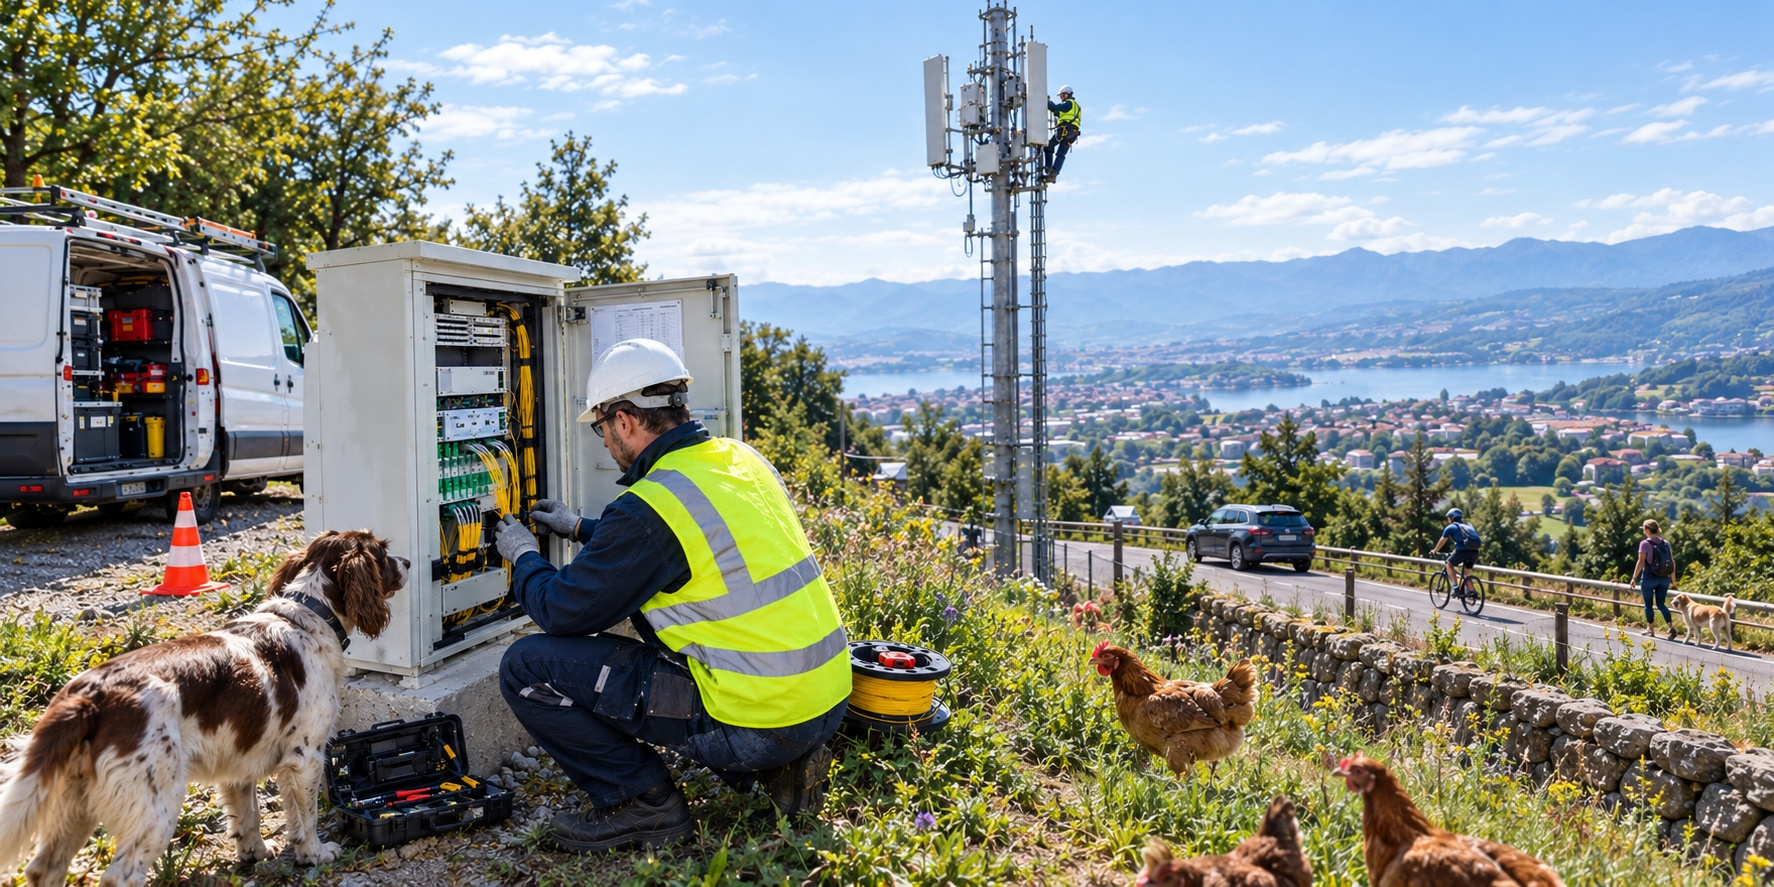

In [7]:
image = cv2.imread(str(TEST_IMAGE))          # BGR numpy array, shape (height, width, 3)
if image is None:
    raise FileNotFoundError(f"Could not read {TEST_IMAGE}: put the test image there, or change TEST_IMAGE.")

height, width = image.shape[:2]
print(f"{TEST_IMAGE.name}: {width} x {height} px, {TEST_IMAGE.stat().st_size / 1e6:.1f} MB")
show(image)

Load the model once up front. The first call downloads the weights (~24 MB) and builds the network, so doing it here keeps the timing below meaningful.

6 objects in 175 ms

Most confident detections (what a Detection looks like):
  dog      0.99  box=[10, 527, 417, 887]
  person   0.98  box=[481, 358, 851, 842]
  car      0.81  box=[1193, 505, 1320, 576]
  truck    0.72  box=[4, 228, 309, 529]

Objects per class: {'person': 3, 'car': 1, 'truck': 1, 'dog': 1}


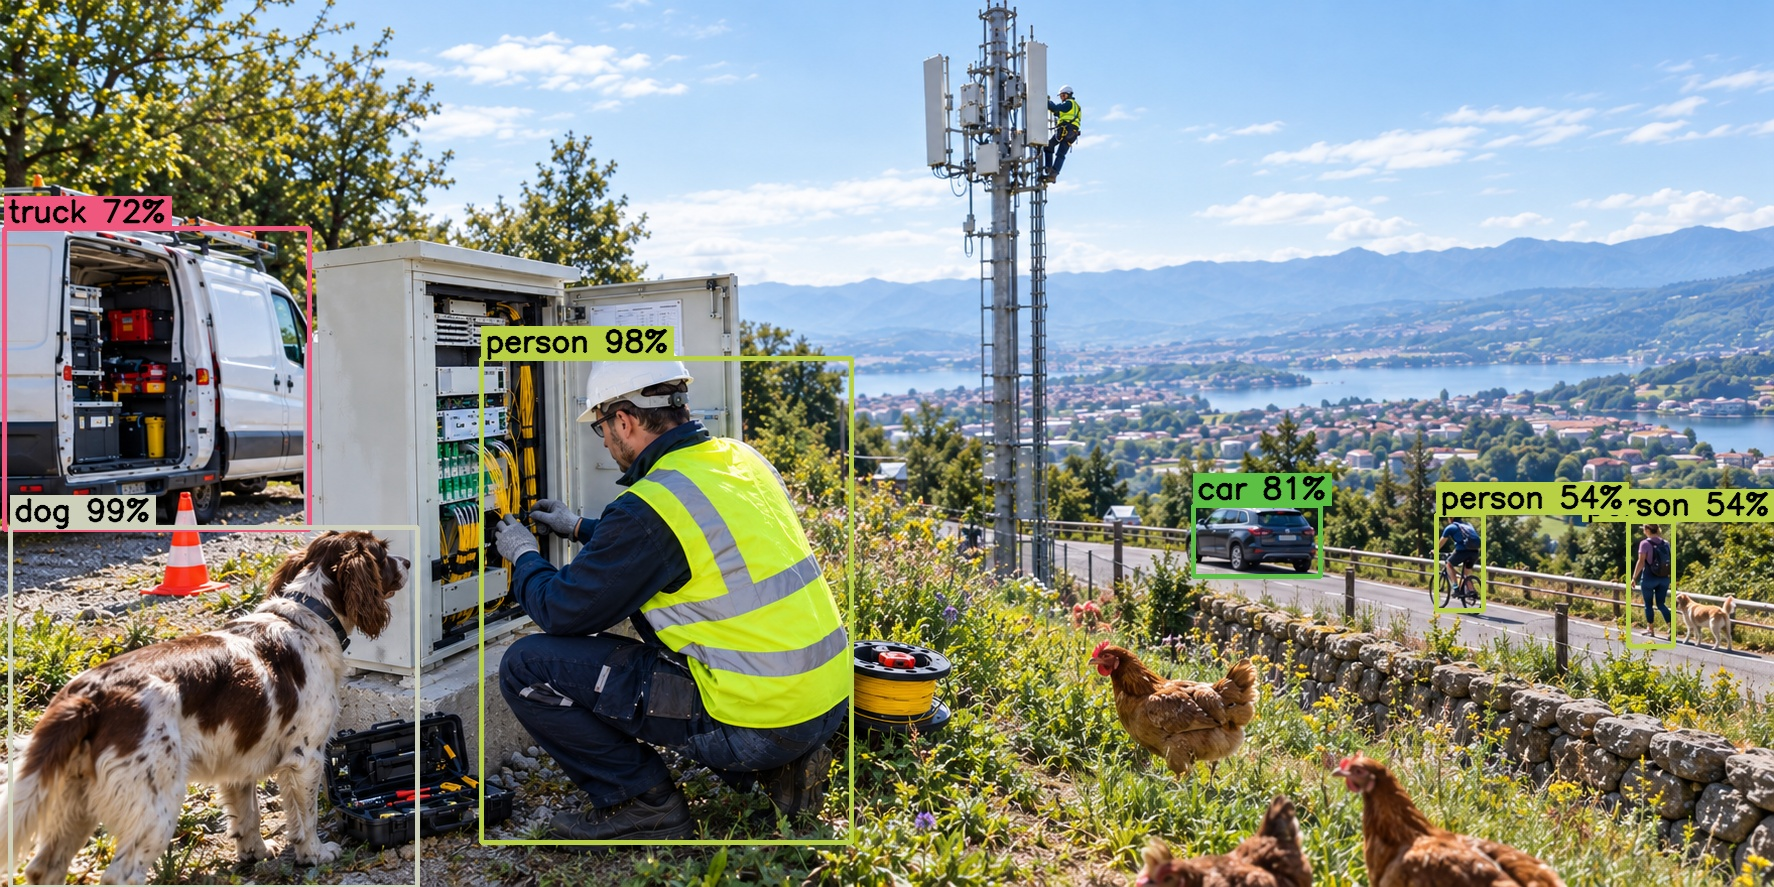

In [8]:
load_model(DEFAULT_MODEL)

start = time.perf_counter()
detections = detect(image)
print(f"{len(detections)} objects in {(time.perf_counter() - start) * 1000:.0f} ms\n")

print("Most confident detections (what a Detection looks like):")
for d in sorted(detections, key=lambda d: d.confidence, reverse=True)[:4]:
    print(f"  {d.label:<8} {d.confidence:.2f}  box={d.box}")

print("\nObjects per class:", dict(Counter(d.label for d in detections)))
show(draw_detections(image, detections))

### Read the result critically

People, cars, the bus, a bicycle and some of the pigeons are found, which is respectable for such a small model. Now look at what is **missing**: the large golden retriever is not detected at all, and neither are the other dog, the bench or the boats.

Why, and what can be done about it? Two knobs matter.

### Choosing the confidence threshold

A detector proposes many candidate boxes, each with a score. Two parameters decide which survive:

- **`confidence`**: the minimum score to report an object. *Lower* finds more objects (higher recall) but admits more false alarms; *higher* gives fewer, more reliable detections but misses objects.
- **Non-maximum suppression (`NMS_THRESHOLD`)**: several boxes usually fire on the same object. NMS keeps the most confident one and drops neighbours **of the same class** that overlap it by more than the threshold.

Count what each threshold finds, on the whole picture and on each scene separately (a plain NumPy slice cuts the picture in half):

In [9]:
scenes = {
    "whole image": image,
    "street": image[:, : width // 2],         # left half
    "riverside": image[:, width // 2 :],      # right half
}
THRESHOLDS = (0.8, 0.5, 0.3, 0.2)

print(f"{'view':<14}" + "".join(f"conf>{t:<7}" for t in THRESHOLDS))
for name, view in scenes.items():
    counts = [len(detect(view, confidence=t)) for t in THRESHOLDS]
    print(f"{name:<14}" + "".join(f"{c:<12}" for c in counts))

view          conf>0.8    conf>0.5    conf>0.3    conf>0.2    
whole image   3           6           8           8           
street        2           3           3           3           
riverside     3           6           6           7           


The table shows two lessons.

**1. A lower threshold finds more objects.** The count grows steadily from 0.8 down to 0.2.

**2. Smaller inputs can beat one big picture.** At 0.5 the two scenes yield 10 + 10 = 20 objects, against 16 for the whole image. The network resizes every input to 416 x 416 px, so a 1536 x 1024 picture is squeezed hard and small things (distant pedestrians, pigeons) shrink to a few pixels. Cropping gives the model more pixels per object. This idea, called **tiling**, is standard in aerial and medical imaging.

Now see the threshold's effect on the picture itself. At 0.2 the retriever, the second dog, the bench, the boats and some backpacks appear:

confidence > 0.1: 8 objects -> {'person': 3, 'car': 1, 'truck': 1, 'bird': 1, 'dog': 1, 'backpack': 1}

The animals:
  dog  0.99  box=[10, 527, 417, 887]


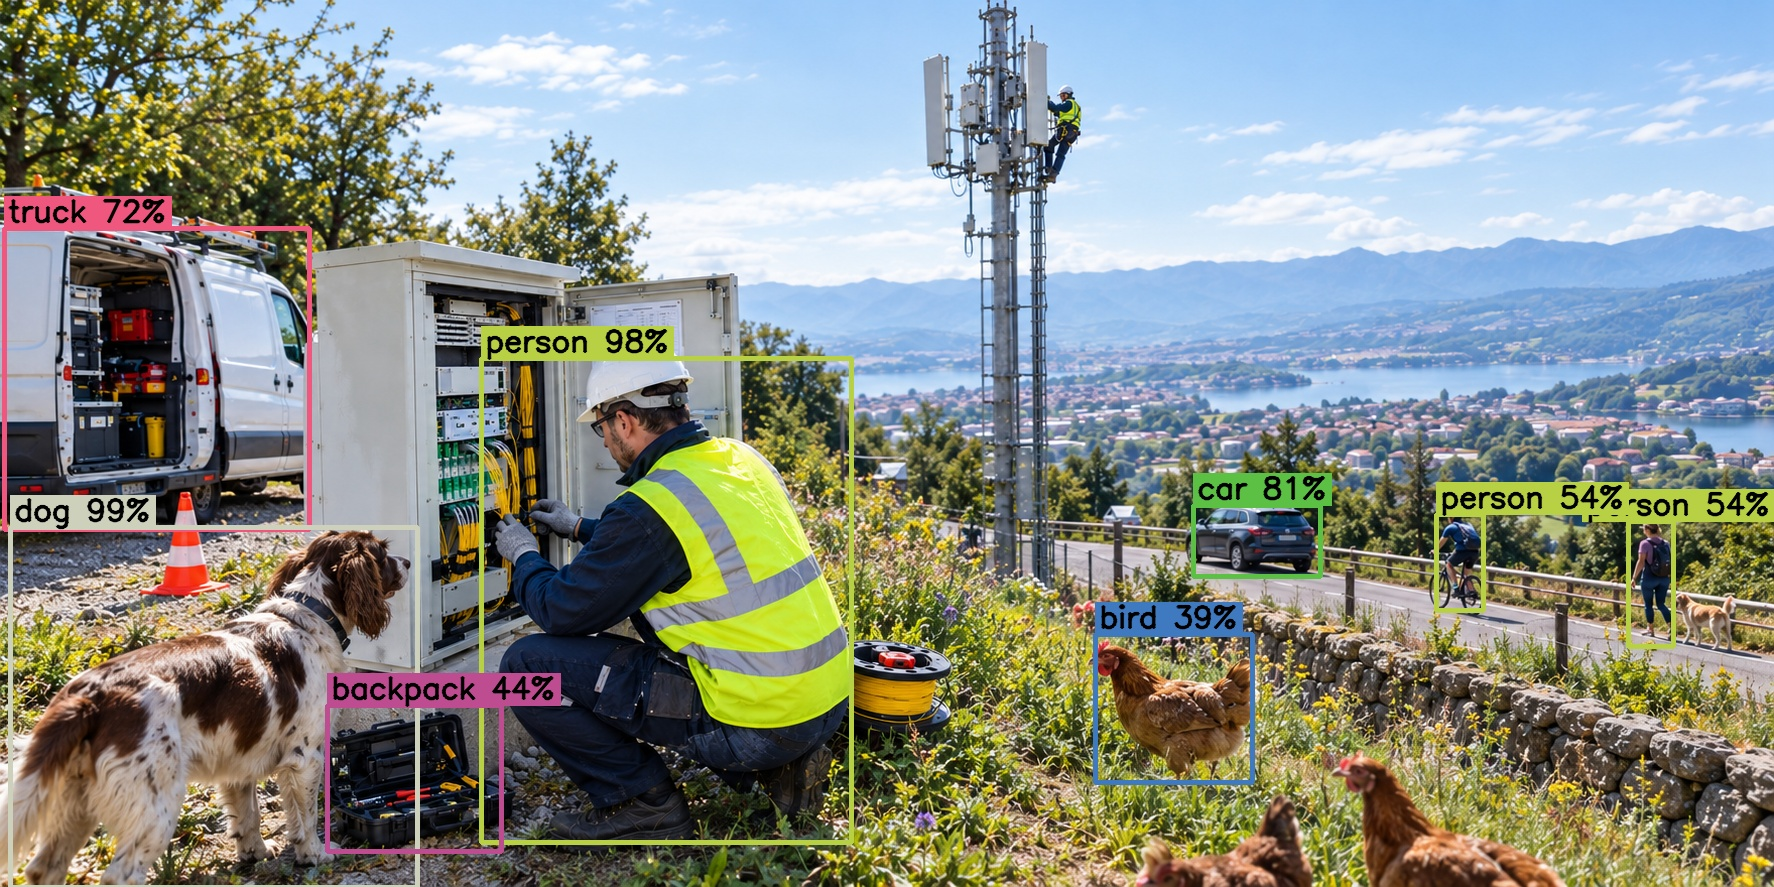

In [10]:
detections = detect(image, confidence=0.2)
print(f"confidence > 0.1: {len(detections)} objects ->", dict(Counter(d.label for d in detections)))

print("\nThe animals:")
for d in detections:
    if d.label in ("dog", "cow"):
        print(f"  {d.label:<4} {d.confidence:.2f}  box={d.box}")
show(draw_detections(image, detections))

Most of the extra boxes are **real** objects the default setting missed: the dogs from 0.3 down (the retriever scores only 44%, below the default cut-off), then the bench, boats and backpacks at 0.2. The price is visible too. The printout shows the retriever receiving both a `dog` box (44%) and a wrong **`cow`** box (36%) at almost the same place: NMS only suppresses duplicates *within* a class, so both survive (in the picture the two labels overlap). The crowded street also fills with overlapping boxes.

There is no universally right value: pick it for the application. A system that must not miss anything (safety alerts) tolerates false alarms; one that triggers an action automatically (billing, blocking) needs high precision. That is why the API below **exposes `confidence` as a parameter** instead of fixing it.

The other lever is the model itself. The full-size `yolov4` finds the retriever with about 99% confidence at the default threshold, but runs an order of magnitude or more slower on a CPU. Part 2 compares both through the API.

Models are not perfect either: expect misses and mislabelled objects, and account for them when the output feeds real decisions.

## 4 · The API layer

| Method | Path | Purpose | Response |
|---|---|---|---|
| GET | `/` | health check | JSON |
| GET | `/models` | list selectable models | JSON |
| POST | `/predict/json` | detect objects | JSON list of detections |
| POST | `/predict/image` | detect objects and draw the boxes | JPEG image |

Two output formats are deliberate: **JSON** is what programs consume (count objects, trigger alerts), an **annotated image** is what humans like to look at.

The code is split into three cells: the app and its schemas, a reusable input-validation *dependency*, then the endpoints.

In [ ]:
@asynccontextmanager
async def lifespan(app: FastAPI):
    """Code before `yield` runs once at server start-up, code after it at shutdown."""
    load_model(DEFAULT_MODEL)       # pay the loading cost now, not on the first user's request
    yield


app = FastAPI(
    title="Object Detection API",
    description="Upload an image, get back the objects detected in it (YOLO, 80 COCO classes).",
    version="1.0.0",
    lifespan=lifespan,
)

# An Enum built from the registry: the API accepts exactly the models we can serve, the docs render it
# as a drop-down, and any other value is rejected with a 422 before our code runs.
ModelName = Enum("ModelName", {name.replace("-", "_"): name for name in MODEL_SPECS}, type=str)


class DetectionResult(BaseModel):
    """Response schema of /predict/json. FastAPI validates the output against it and documents it."""
    model: str
    count: int
    detections: list[Detection]

**Dependencies** let several endpoints share logic. `read_image` turns an upload into an OpenCV image and fails with a precise HTTP error otherwise; both prediction endpoints reuse it.

In [ ]:
def read_image(file: Annotated[UploadFile, File(description="JPEG or PNG image")]) -> np.ndarray:
    """Dependency: uploaded file -> OpenCV image, or a clear HTTP error."""
    data = file.file.read()
    if len(data) > MAX_UPLOAD_MB * 1024 * 1024:
        raise HTTPException(status_code=413, detail=f"Image is larger than {MAX_UPLOAD_MB} MB.")

    # Validate by actually *decoding*: file extensions and Content-Type headers are chosen by the client.
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise HTTPException(status_code=415, detail="Unsupported file: it could not be decoded as an image.")
    return image


# Reusable parameter types: "fill this parameter by calling read_image()" and shared query-parameter rules.
UploadedImage = Annotated[np.ndarray, Depends(read_image)]
ModelParam = Annotated[ModelName, Query(description="Which model to run")]
ConfidenceParam = Annotated[float, Query(ge=0.0, le=1.0, description="Minimum confidence to report an object")]

In [ ]:
@app.get("/")
def health():
    """Health check: confirms the server is up."""
    return {"status": "ok", "docs": "/docs"}


@app.get("/models")
def list_models():
    """Models this server can run."""
    return {"models": list(MODEL_SPECS), "default": DEFAULT_MODEL}


# Plain `def`, not `async def`, on purpose: inference is CPU-bound and blocking. FastAPI runs plain functions
# in a thread pool, so one slow prediction does not freeze the whole server.
@app.post("/predict/json", response_model=DetectionResult)
def predict_json(
    image: UploadedImage,
    model: ModelParam = ModelName(DEFAULT_MODEL),
    confidence: ConfidenceParam = DEFAULT_CONFIDENCE,
):
    """Detect objects and return them as JSON."""
    detections = detect(image, model.value, confidence)
    return DetectionResult(model=model.value, count=len(detections), detections=detections)


@app.post("/predict/image", response_class=Response, responses={200: {"content": {"image/jpeg": {}}}})
def predict_image(
    image: UploadedImage,
    model: ModelParam = ModelName(DEFAULT_MODEL),
    confidence: ConfidenceParam = DEFAULT_CONFIDENCE,
):
    """Detect objects and return the image with boxes and labels drawn on it."""
    detections = detect(image, model.value, confidence)
    _, buffer = cv2.imencode(".jpg", draw_detections(image, detections))
    return Response(
        content=buffer.tobytes(),
        media_type="image/jpeg",
        headers={"X-Object-Count": str(len(detections))},   # extra metadata travels in a response header
    )

## 5 · Run the server

Uvicorn normally blocks the process it runs in, which would freeze the notebook. Here it starts in a **background thread**, so the notebook stays usable and the server can be stopped cleanly. (The alternative, `uvicorn.run(app)`, blocks the cell until you interrupt the kernel and needs `nest_asyncio` inside notebooks.)

> **Note on `HOST`.** `127.0.0.1` accepts connections from this machine only. Use `0.0.0.0` only when other machines or containers must reach the server, and be aware that you are then exposing it to the network.

In [ ]:
_server = None
_thread = None


def start_server(host: str = HOST, port: int = PORT) -> None:
    """Start Uvicorn in a background thread and wait until it accepts connections."""
    global _server, _thread
    if _thread is not None and _thread.is_alive():
        print("Server is already running.")
        return

    _server = uvicorn.Server(uvicorn.Config(app, host=host, port=port, log_level="info"))
    _thread = threading.Thread(target=_server.run, daemon=True)
    _thread.start()

    deadline = time.time() + 15
    while not _server.started and _thread.is_alive() and time.time() < deadline:
        time.sleep(0.1)          # `started` flips to True once the socket is listening

    if _server.started:
        print(f"Server running at http://{host}:{port}   (interactive docs: /docs)")
    else:
        print("Server failed to start. Check the log above (is the port already in use?).")


def stop_server() -> None:
    """Ask Uvicorn to shut down gracefully and wait for its thread to finish."""
    if _server is not None and _thread.is_alive():
        _server.should_exit = True
        _thread.join(timeout=10)
        print("Server stopped.")

In [ ]:
start_server()

Uvicorn logs one line per request. They appear below the cell that is currently running, which can look odd in a notebook but is harmless.

Quick check from the notebook itself:

In [ ]:
print(requests.get(f"http://{HOST}:{PORT}/").json())
print(requests.get(f"http://{HOST}:{PORT}/models").json())

### Explore the interactive docs

FastAPI generates documentation from your code. Open **http://127.0.0.1:8000/docs** in a browser (Swagger UI) and:

1. Expand **POST /predict/image** and click **Try it out**.
2. Choose a `model` and a `confidence` value.
3. Pick an image under `file` (for example `images/paris_cars_people.png`), then click **Execute**.
4. The annotated image appears under *Response body*; the object count is in the `x-object-count` response header.
5. Break it on purpose: upload a text file (expect **415**), or set `confidence` to `2` (expect **422**).

Also generated for free: `/redoc` (an alternative reading view) and `/openapi.json` (the machine-readable specification, usable to generate client libraries).

> Running on a remote or hosted notebook? `127.0.0.1` refers to the machine running the kernel, not your laptop. Use the platform's port-forwarding or proxy URL, and bind to `0.0.0.0`.

**Leave the server running and continue with [Part 2](client.ipynb).** When you are completely done, run the cell below to shut it down.

In [ ]:
# stop_server()      # <- uncomment and run when you have finished with Part 2

## 6 · Design notes, troubleshooting, next steps

### Why the code looks the way it does

| Decision | Reason |
|---|---|
| Plain `def` endpoints | Inference blocks. FastAPI runs plain functions in a thread pool; an `async def` that does heavy work would freeze the event loop and stall every other request. |
| Model loaded once (`lru_cache` + `lifespan`) | Loading takes seconds, inference takes milliseconds. Reloading per request would make each call hundreds of times slower. |
| Lock around inference | A single OpenCV network instance is not meant to run concurrent forward passes; the lock serialises them safely. |
| Validate by decoding the file | Extensions and `Content-Type` headers are supplied by the client and can lie. |
| Process images in memory, never build paths from the uploaded file name | A name such as `../../etc/x.jpg` is a classic path-traversal attack, and files written per request pile up. |
| Size limit | Protects server memory. In production also enforce it at the reverse proxy. |
| `Enum` and `Query(ge=, le=)` | Invalid input is rejected with a descriptive 422 before your code runs, so there is less defensive code to write. |
| `response_model` | Output is validated and documented, so the contract with clients stays explicit. |
| Registry (`MODEL_SPECS`) | Adding a model is one entry, not a new code path. |

### Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `Form data requires "python-multipart"` at start-up | missing dependency | `%pip install python-multipart`, then restart the kernel |
| "Server failed to start" / address already in use | another process, or an earlier server, holds the port | `stop_server()`, or change `PORT` |
| You edited the code but behaviour did not change | the running server still holds the *old* `app` | `stop_server()`, re-run the app cells, `start_server()` |
| First request with `yolov4` hangs | the server is downloading ~250 MB of weights | run `load_model("yolov4")` in a cell first (same process, so the cache is shared), or raise the client timeout |
| Downloads fail behind a proxy or firewall | GitHub is unreachable | download the files manually into `models/` under the same file names |
| `FileNotFoundError: Could not read images/paris_cars_people.png` | the notebook was started from another folder | run Jupyter from the folder that contains `images/`, or change `TEST_IMAGE` |
| Another machine or a container cannot connect | the server is bound to `127.0.0.1` | set `HOST = "0.0.0.0"` and open the port |

### Where to go next

- **Run it as a script.** Copy the code cells of sections 1, 3 and 4 into `app.py`, then run `uvicorn app:app --host 127.0.0.1 --port 8000`. Add `--workers N` for several processes (each loads its own copy of the model). Package it in a Docker image for deployment.
- **Test without a network.** `fastapi.testclient.TestClient(app)` calls the endpoints in-process (requires `httpx`), ideal for automated tests.
- **Secure it.** API keys or OAuth2 (`fastapi.security`), HTTPS through a reverse proxy, rate limiting.
- **Scale it.** GPU inference (OpenCV CUDA backend, ONNX Runtime), request batching, a job queue for slow tasks, or a dedicated model server such as Triton.
- **Operate it.** Structured logging, metrics, health and readiness probes, versioned paths (`/v1/predict`), model versioning.
- **Serve other model types.** Same pattern; for tabular or text models the input is a JSON body described by a Pydantic class instead of a file:

```python
class Features(BaseModel):
    age: int
    income: float

@app.post("/predict")
def predict(features: Features):              # JSON body, validated automatically
    return {"score": float(my_model.predict([[features.age, features.income]])[0])}
```

### Key takeaways

1. Develop and test the **model logic first**, then wrap it; the API layer stays thin.
2. **Load once, validate input, never trust the client** (file names, extensions, headers, sizes).
3. **Declare types** and let FastAPI provide parsing, validation, error responses and documentation.
4. Use **meaningful status codes** so clients can react correctly (4xx = fix your request, 5xx = server problem).
5. Keep blocking inference in plain `def` endpoints, and design for the load you expect.

**Next:** [Part 2 · Building a client](client.ipynb)